# Session 6 · Testing the model and inspecting one crop

I used the checkpoint picked in Session 5 for both the demo and the held-out evaluation. Given a crop containing a defect, it returns six scores and a predicted class. NEU-CLS has no defect-free class, so a pass/fail decision is outside what I measured here.

To try one image, run the first two code cells from the project folder.

In [ ]:
from pathlib import Path
import hashlib
import json
import platform
from time import perf_counter_ns

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import torch
from torch import nn

artifacts = Path("Artifacts")
selection = json.loads((artifacts / "session5_selection.json").read_text(encoding="utf-8"))
checkpoint = artifacts / selection["selected_checkpoint"]
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == selection["checkpoint_sha256"]
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
classes = saved["classes"]
assert classes == selection["classes"] and len(classes) == 6
assert saved["manifest_sha256"] == selection["manifest_sha256"]
assert saved["architecture"] == "deep_cnn_bn" and saved["batch_norm"]
assert saved["input_shape"] == [1, 200, 200]
torch.set_num_threads(min(4, torch.get_num_threads()))

layers = []
channels = 1
for outputs, kernel, stride in zip(saved["channels"], [5, 3, 3], [2, 1, 1], strict=True):
    layers.extend([nn.Conv2d(channels, outputs, kernel, stride, padding=kernel // 2),
                   nn.BatchNorm2d(outputs), nn.ReLU(), nn.MaxPool2d(2)])
    channels = outputs
layers.extend([nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(channels * 16, len(classes))])
model = nn.Sequential(*layers).to(memory_format=torch.channels_last)
model.load_state_dict(saved["state_dict"])
model.eval()

def read_crop(path):
    with Image.open(path) as source:
        crop = ImageOps.exif_transpose(source).convert("L")
        if crop.size != (200, 200):
            crop = crop.resize((200, 200), Image.Resampling.BILINEAR)
        return np.array(crop)

def make_input(pixels):
    values = torch.from_numpy(pixels).float() / 255.0
    return ((values - saved["mean"]) / saved["std"]).reshape(1, 1, 200, 200)

@torch.inference_mode()
def inspect_crop(path):
    pixels = read_crop(path)
    scores = model(make_input(pixels)).softmax(dim=1)[0].tolist()
    return pixels, classes[int(np.argmax(scores))], dict(zip(classes, scores))

## Trying a local image

Set `image_path` to a local defect crop and run the cell. The image on the left is what the network sees after conversion to grayscale and resizing to 200 × 200. The bars show all six softmax scores. The displayed time runs from opening the file to returning the scores with the model already loaded.

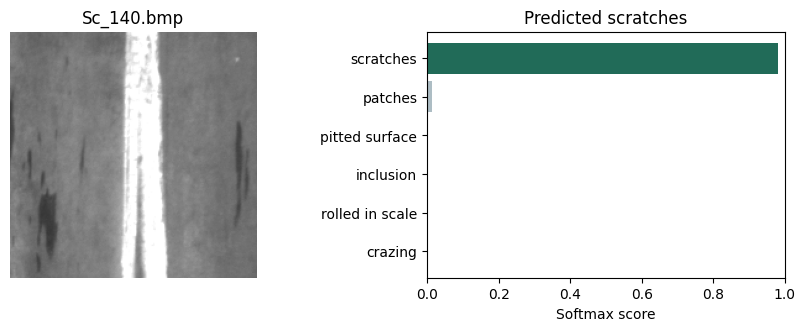

,Softmax score
scratches,0.980732
patches,0.014559
pitted_surface,0.002459
inclusion,0.001970
rolled_in_scale,0.000210
crazing,0.000071


Single inspection: 33.67 ms


In [ ]:
image_path = Path("Dataset/NEU-CLS/Sc_250.bmp")  
start = perf_counter_ns()
pixels, prediction, scores = inspect_crop(image_path)
elapsed_ms = (perf_counter_ns() - start) / 1e6

fig, (left, right) = plt.subplots(1, 2, figsize=(8.5, 3.2), layout="constrained")
left.imshow(pixels, cmap="gray", vmin=0, vmax=255)
left.set_title(image_path.name)
left.axis("off")
names = sorted(scores, key=scores.get)
right.barh([name.replace("_", " ") for name in names], [scores[name] for name in names],
           color=["#216b58" if name == prediction else "#adbdc4" for name in names])
right.set(xlim=(0, 1), xlabel="Softmax score", title="Predicted " + prediction.replace("_", " "))
plt.show()
display(pd.Series(scores, name="Softmax score").sort_values(ascending=False).to_frame())
print(f"Single inspection: {elapsed_ms:.2f} ms")

## Scoring the held-out images

I checked the saved checkpoint and split digests and checked every test crop against its Session 1 pixel hash. I used the same prediction function as the demo. In the matrix, each row contains the 45 examples of one true class, and each column shows where the model assigned them.

Test macro F1 0.9557 | 258/270 correct


,precision,recall,f1-score,support
crazing,1.0000,0.9111,0.9535,45.0
inclusion,0.8936,0.9333,0.9130,45.0
patches,0.9184,1.0000,0.9574,45.0
pitted_surface,1.0000,0.9778,0.9888,45.0
rolled_in_scale,1.0000,1.0000,1.0000,45.0
scratches,0.9318,0.9111,0.9213,45.0


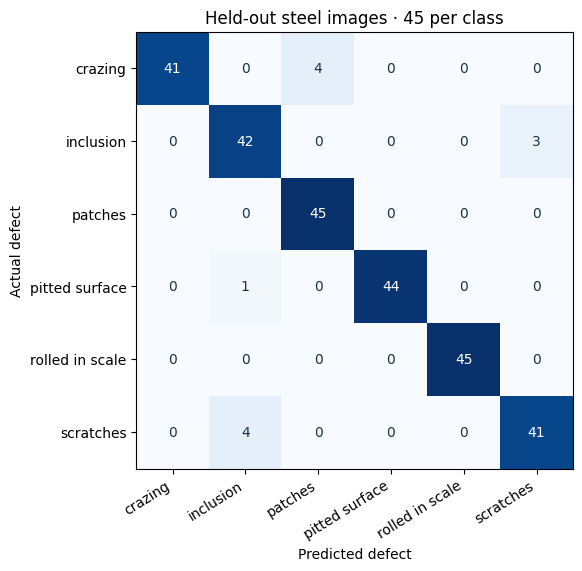

In [ ]:
manifest_path = artifacts / "split_manifest.csv"
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == selection["manifest_sha256"]
manifest = pd.read_csv(manifest_path)
test = manifest.loc[manifest.split == "test"].reset_index(drop=True)
assert len(test) == 270 and test.label.value_counts().reindex(classes).eq(45).all()
assert set(test.pixel_sha256).isdisjoint(manifest.loc[manifest.split != "test", "pixel_sha256"])
records = []
for row in test.itertuples(index=False):
    with Image.open(row.path) as image:
        if image.mode != "L" or image.size != (200, 200):
            raise ValueError(f"Unexpected test image format: {row.path}")
        if hashlib.sha256(image.tobytes()).hexdigest() != row.pixel_sha256:
            raise ValueError(f"Unexpected pixels: {row.path}")
    _, predicted, probabilities = inspect_crop(row.path)
    records.append({"path": row.path, "actual": row.label, "predicted": predicted, "scores": probabilities})

cases = pd.DataFrame(records)
cm = confusion_matrix(cases.actual, cases.predicted, labels=classes)
report = classification_report(cases.actual, cases.predicted, labels=classes, output_dict=True, zero_division=0)
macro_f1 = float(f1_score(cases.actual, cases.predicted, labels=classes, average="macro"))
assert cm.sum() == 270 and int(cm.trace()) == (cases.actual == cases.predicted).sum()
print(f"Test macro F1 {macro_f1:.4f} | {cm.trace()}/{cm.sum()} correct")
display(pd.DataFrame(report).T.loc[classes, ["precision", "recall", "f1-score", "support"]].round(4))
fig, ax = plt.subplots(figsize=(6.7, 5.6), layout="constrained")
ax.imshow(cm, cmap="Blues", vmin=0, vmax=45)
labels = [name.replace("_", " ") for name in classes]
ax.set(xticks=range(6), yticks=range(6), xticklabels=labels, yticklabels=labels,
       xlabel="Predicted defect", ylabel="Actual defect", title="Held-out steel images · 45 per class")
plt.setp(ax.get_xticklabels(), rotation=32, ha="right")
for i, j in np.ndindex(cm.shape):
    ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > 22 else "#183249")
fig.savefig(artifacts / "test_confusion_matrix.png", dpi=150)
plt.show()

## Looking at the twelve mistakes

Four scratches went to inclusion and three inclusions went to scratches. Another four crazing images went to patches. The gallery shows three of those crazing crops beside a correctly predicted patch. The crazing crops have broad, uneven gray regions. The patch in `Pa_109` has a more sharply defined dark mark. My initial guess about crazing and rolled-in scale had zero errors in either direction on the test split.

,,errors
actual,predicted,
crazing,patches,4
scratches,inclusion,4
inclusion,scratches,3
pitted_surface,inclusion,1


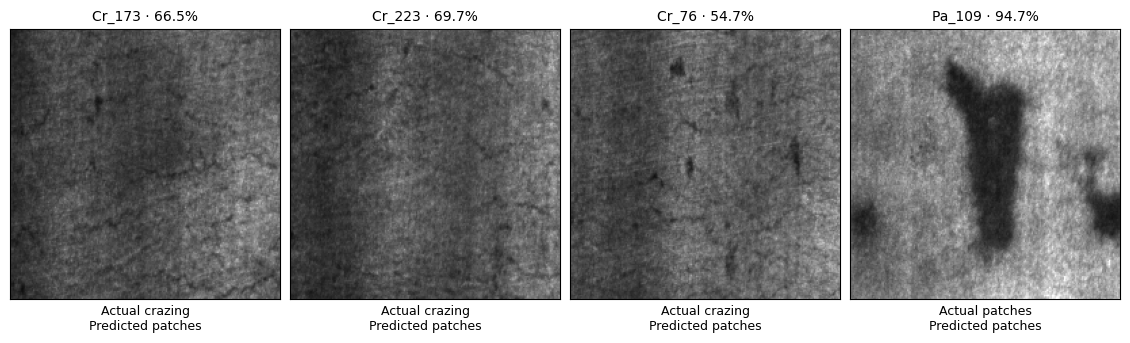

In [ ]:
errors = cases.loc[cases.actual != cases.predicted]
if errors.empty:
    print("All test images were classified correctly.")
else:
    directions = errors.groupby(["actual", "predicted"]).size().sort_values(ascending=False)
    display(directions.rename("errors").to_frame())
    actual_label, guessed_label = directions.index[0]
    examples = errors.loc[(errors.actual == actual_label) & (errors.predicted == guessed_label)].head(3)
    reference = cases.loc[(cases.actual == guessed_label) & (cases.predicted == guessed_label)].head(1)
    gallery = pd.concat([examples, reference])
    fig, axes = plt.subplots(1, len(gallery), figsize=(2.8 * len(gallery), 3.1), squeeze=False, layout="constrained")
    for ax, row in zip(axes.flat, gallery.itertuples(index=False)):
        ax.imshow(read_crop(row.path), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{Path(row.path).stem} · {row.scores[row.predicted]:.1%}", fontsize=10)
        ax.set_xlabel(f"Actual {row.actual.replace('_', ' ')}\nPredicted {row.predicted.replace('_', ' ')}", fontsize=9)
        ax.set(xticks=[], yticks=[])
    plt.show()

## Timing one inspection

I measured two paths on CPU with batch size one. One starts from a normalized tensor. The other reopens a local file and includes decoding, preprocessing, the forward pass and returning the label and scores. I warmed each path with 30 images and timed 270 calls in the same seeded order. File reads could use the OS cache. Camera acquisition, model loading and plotting sit outside these timings.

In [ ]:
def cpu_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    if Path("/proc/cpuinfo").exists():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor() or platform.machine()

paths = test.sample(frac=1, random_state=42).path.tolist()
inputs = [make_input(read_crop(path)) for path in paths]

@torch.inference_mode()
def benchmark(inputs, operation):
    for item in inputs[:30]:
        operation(item)
    times = []
    for item in inputs:
        start = perf_counter_ns()
        operation(item)
        times.append((perf_counter_ns() - start) / 1e6)
    return {"median_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95))}

latency = {"cpu": cpu_name(), "torch": str(torch.__version__), "os": platform.system(),
           "threads": torch.get_num_threads(), "batch_size": 1, "warmup_per_path": 30,
           "samples_per_path": len(paths), "forward": benchmark(inputs, model),
           "file_to_scores": benchmark(paths, inspect_crop)}
print(f"{latency['cpu']} | {latency['threads']} PyTorch threads | PyTorch {latency['torch']}")
display(pd.DataFrame({name: latency[name] for name in ["forward", "file_to_scores"]}).T.round(3))

Intel(R) Core(TM) i7-8650U CPU @ 1.90GHz | 4 PyTorch threads | PyTorch 2.13.0+cpu


,median_ms,p95_ms
forward,2.238,7.657
file_to_scores,4.300,7.771


## Where the project finished

The 5,318-parameter CNN got 258 of 270 test crops right, with 0.9557 macro F1. Reading a local crop and returning its scores took a median of 4.30 ms on the measured CPU. The table below puts each development run on the same validation metric. I saved the final test predictions separately so I could trace any error back to its image.

In [ ]:
stages = {"Fully connected ANN": "ann_validation.json", "Basic CNN": "basic_cnn_validation.json",
          "Deeper CNN": "deep_cnn_validation.json", "Deeper CNN + BN": "deep_cnn_bn_validation.json",
          "Optimized CNN": selection["selected_report"]}
progression = []
for stage, filename in stages.items():
    previous = json.loads((artifacts / filename).read_text(encoding="utf-8"))
    assert previous["manifest_sha256"] == selection["manifest_sha256"] and previous["classes"] == classes
    progression.append({"stage": stage, "parameters": previous["parameters"],
                        "validation_macro_f1": previous["validation_macro_f1"]})
display(pd.DataFrame(progression).set_index("stage").round(4))
result = {"checkpoint": checkpoint.name, "checkpoint_sha256": selection["checkpoint_sha256"],
          "manifest_sha256": selection["manifest_sha256"], "epoch": saved["epoch"], "classes": classes,
          "test_count": len(cases), "correct": int(cm.trace()), "accuracy": float(cm.trace() / cm.sum()),
          "macro_f1": macro_f1, "classification_report": report, "confusion_matrix": cm.tolist(),
          "cpu_latency": latency, "progression": progression, "predictions": records}
target = artifacts / "final_test_report.json"
temporary = target.with_suffix(".tmp")
temporary.write_text(json.dumps(result, indent=2), encoding="utf-8")
temporary.replace(target)

,parameters,validation_macro_f1
stage,,
Fully connected ANN,2560454,0.5011
Basic CNN,2918,0.7118
Deeper CNN,5238,0.8480
Deeper CNN + BN,5318,0.9408
Optimized CNN,5318,0.9816


WindowsPath('Artifacts/final_test_report.json')